In [ ]:
pip install engineering_notation

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from engineering_notation import EngNumber
from matplotlib.widgets import Slider, Button
from matplotlib.colors import Normalize
import matplotlib.cm as cm
import cmath
import matplotlib.colors as mcolors
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter,AutoMinorLocator)

# Dados do Transformador e do Filtro

# Lactec Relatório

| $f_0[\rm{Hz}]$| $V[\rm{V}]$   | $P[\rm{MVA}]$ | $C[\rm{\mu F}]$  	| $L \,[\rm{m H}]$ 	| $R_L \,[\rm{\Omega}]$ | $R \,[\rm{\Omega}]$ |
|---------------|------	        |------	        |------	            |--------	        |-------	            |---	              |
| 120   	    | 34.5 	        | 2.00 	        | 3.34 	            | 526.21 	        | 3.31  	            | 0.00 	              |
| 180   	    | 34.5 	        | 3.00 	        | 5.94 	            | 131.55 	        | 1.86  	            | 0.00 	              |
| 300   	    | 34.5 	        | 3.60 	        | 7.70 	            | 36.54  	        | 0.86  	            | 0.00	              |



In [ ]:
V_fund = 34.5e3
f_fund = 60
w_fund = 2*np.pi*f_fund

S_trafo = 60e6
Z_baseTrafo = V_fund**2 / S_trafo
Z_trafo = ( 1.2e-3 + 1j*61e-3) * Z_baseTrafo

Q_filtro = 2.8e6 # potência reativa

FQual = np.array([20, 80])

In [ ]:
X_F = V_fund**2 / Q_filtro

### Fator de Qualidade $ Q_0 $ e Amorteciomento $ \zeta $


$$Q_0 = 2\pi \frac{{{W_{{\text{max_armazenada}}}}}}{{{W_{{\text{perdida}}}}}}=2\pi \frac{{\frac{{L{I^2}}}{2}}}{{R{I^2}\frac{{2\pi }}{f}}} = \frac{{\omega L}}{R} = \frac{1}{{\omega CR}} = \frac{{\sqrt {\frac{L}{C}} }}{R}$$
$$ $$
$$\zeta = \frac{1}{{2{Q_0}}}$$

com

$${s^2} + \left( {2\zeta {\omega _0}} \right)s + \omega _o^2 = 0$$

vindo de 

$${s^2} + \frac{1}{{RC}}s + \frac{1}{{LC}} = 0$$

vale a pena saber

$${s^2} + \left( {2\zeta {\omega _0}} \right)s + \omega _o^2 = 0$$
$$ $$
$$s =  - \underbrace {\zeta {\omega _0}}_\alpha  \pm j\underbrace {{\omega _0}\sqrt {1 - {\zeta ^2}} }_{{\omega _d}}$$


### Largura de Banda em função do fator de qualidade
$${\omega _{1,2}} = {\omega _0}\left[ {\sqrt {1 + {{\left( {\frac{1}{{2{Q_0}}}} \right)}^2}}  \mp \frac{1}{{2{Q_0}}}} \right] \approx {\omega _0}\left[ {1 \mp \underbrace {\frac{1}{{2{Q_0}}}}_{\frac{1}{2}\beta }} \right]$$

In [ ]:
h_filtrar = 3
d = 0/100
h_0 = (1-d)*h_filtrar
h02 = h_0**2

$${h_0}\,\omega  = \frac{1}{{\sqrt {L\,C} }} \Rightarrow h_0^2 = \frac{1}{{{\omega ^2}L\,C}} = \frac{1}{{\omega \,C\,\omega L}} = \frac{{{X_C}}}{{{X_L}}}$$

$$\left. \begin{gathered}
  {X_F} = {X_C} - {X_L} \hfill \\
  h_0^2 = \frac{{{X_C}}}{{{X_L}}} \hfill \\ 
\end{gathered}  \right\} \Rightarrow \left\{ \begin{gathered}
  {X_C} = \frac{1}{{h_0^2 - 1}}{X_F} \hfill \\
  {X_C} = \frac{{h_0^2}}{{h_0^2 - 1}}{X_F} \hfill \\ 
\end{gathered}  \right.$$

In [ ]:
X_L =   1/(h02-1) * X_F
L = X_L / w_fund

In [ ]:
X_C = h02/(h02-1) * X_F
C = 1 / ( X_C* w_fund )

In [ ]:
f_max = ( 1 / np.sqrt(L*C) ) / ( 2 * np.pi )

In [ ]:
Z0 = np.sqrt(L/C)
R  = Z0 / FQual

In [ ]:
Z_RL = R + 1j*X_L
Y_RL = 1 / Z_RL
R_paralelo = 1 / np.real(Y_RL)
X_L_paralelo = - 1 / np.imag(Y_RL)
L_paralelo = X_L_paralelo / w_fund

## Variação com a frequência

In [ ]:
f = np.arange(60, 1600.1, 0.1)
f = np.round(f,4)
w = 2*np.pi*f


### Filtro

In [ ]:
Zfiltro = np.zeros((len(FQual), len(f)), dtype=np.complex_)
Zmod    = np.zeros((len(FQual), len(f)))
Zang    = np.zeros((len(FQual), len(f)))
for k in range(len(FQual)):
    Zfiltro[k,:] = R[k] + 1j*w*L + 1/(1j*w*C)
    Zmod[k,:]    = np.abs(Zfiltro[k])
    Zang[k,:]    = np.angle(Zfiltro[k], deg=True)

### Transformador

In [ ]:
X_trafo = np.imag(Z_trafo)/w_fund * w
R_trafo = np.real(Z_trafo) * w/w
Z_trafoFreq = R_trafo + 1j*X_trafo

## Filtro em paralelo com o transformador

In [ ]:
Y_filtro = 1 / Zfiltro
Y_trafo  = 1 / Z_trafoFreq
Y_trafoFiltro = Y_filtro + Y_trafo
Z_trafoFiltro = 1 / Y_trafoFiltro

## Filtro @ $60$ Hz, para vários $Q_0$

### Filtro $RLC$ série

In [ ]:
Ifiltro    = np.zeros((len(FQual)), dtype=np.complex_)
Vindutor   = np.zeros((len(FQual)), dtype=np.complex_)
Vcapacitor = np.zeros((len(FQual)), dtype=np.complex_)
Vresistor  = np.zeros((len(FQual)), dtype=np.complex_)
for k in range(len(FQual)):
    Ifiltro[k] = ( V_fund/np.sqrt(3) ) / Zfiltro[k,0]
    Vindutor[k]   =  1j * X_L * Ifiltro[k]
    Vcapacitor[k] = -1j * X_C * Ifiltro[k]
    Vresistor[k]  =      R[k] * Ifiltro [k]
    #conf = np.sqrt(3) * (Vresistor+Vcapacitor+Vindutor)
    #print(conf)

### Filtro $R$//$L+C$

#### Potências nos Elementos do Filtro Série

In [ ]:
Qcap  = np.zeros((len(FQual)), dtype=np.complex_)
Qind  = np.zeros((len(FQual)), dtype=np.complex_)
Qfil  = np.zeros((len(FQual)))
Pfil  = np.zeros((len(FQual)))
for k in range(len(FQual)):
    Qcap[k] = 3 * Vcapacitor[k] * np.conj(Ifiltro[k])
    Qind[k] = 3 * Vindutor[k]   * np.conj(Ifiltro[k])
    Qfil[k] = np.imag( Qcap[k] - Qind[k] )
    Pfil[k] = 3 * R[k] * np.abs(Ifiltro[k])**2

In [ ]:
I_Rparalelo  = np.zeros((len(FQual)), dtype=np.complex_)
I_Lparalelo  = np.zeros((len(FQual)), dtype=np.complex_)
I_Cserie     = np.zeros((len(FQual)), dtype=np.complex_)
V_Cserie     = np.zeros((len(FQual)), dtype=np.complex_)
V_RLparalelo = np.zeros((len(FQual)), dtype=np.complex_)
Zfiltro2     = np.zeros((len(FQual)), dtype=np.complex_)
for k in range(len(FQual)):
    Yrlparalelo     = 1/R_paralelo[k] + 1/(1j*X_L_paralelo[k])
    Zrlparalelo     = 1 / Yrlparalelo
    Zfiltro2[k]     = Zrlparalelo + 1/(1j*w_fund*C)
    I_Cserie[k]     = (V_fund/np.sqrt(3)) / Zfiltro2[k]
    V_RLparalelo[k] = Zrlparalelo * I_Cserie[k]
    I_Rparalelo[k]  = V_RLparalelo[k] / R_paralelo[k]
    I_Lparalelo[k]  = V_RLparalelo[k] / (1j*X_L_paralelo[k])
    V_Cserie[k]     = 1/(1j*w_fund*C)  * I_Cserie[k]
    #conf = np.sqrt(3) * (Vresistor+Vcapacitor+Vindutor)
    #print(conf)

#### Potência nos Elementos do Filtro $R$//$L+C$

In [ ]:
Qcap2  = np.zeros((len(FQual)), dtype=np.complex_)
Qind2  = np.zeros((len(FQual)), dtype=np.complex_)
Qfil2  = np.zeros((len(FQual)))
Pfil2  = np.zeros((len(FQual)))
for k in range(len(FQual)):
    Qcap2[k] = 3 * V_Cserie[k]     * np.conj(I_Cserie[k])
    Qind2[k] = 3 * V_RLparalelo[k] * np.conj(I_Lparalelo[k])
    Pfil2[k] = 3 * R_paralelo[k]   * np.abs(I_Rparalelo[k])**2
    Qfil2[k] = np.imag( Qcap2[k] - Qind2[k] )

## Saídas

In [ ]:
for k in range(len(FQual)):
    print('==========================================================')
    print('No circuito RLC série Q\u2080 =',FQual[k],' \u03B6 =',1/(2*FQual[k]) )
    print('==========================================================')
    print('   R    = ', EngNumber(R[k]))
    print('   L    = ', EngNumber(L))
    print('   C    = ', EngNumber(C))
    print('   Vcap = ', EngNumber(np.abs(Vcapacitor[k])), '\u2221', EngNumber(np.angle(Vcapacitor[k],  deg=True)))
    print('   Vind = ', EngNumber(np.abs(Vindutor[k])),   '\u2221', EngNumber(np.angle(Vindutor[k],    deg=True)))
    print('   Vres = ', EngNumber(np.abs(Vresistor[k])),  '\u2221', EngNumber(np.angle(Vresistor[k],   deg=True)))
    temp = Vcapacitor[k]+Vindutor[k]+Vresistor[k]
    print('   Vtot = ', EngNumber(np.abs(temp)),          '\u2221', EngNumber(np.angle(temp,           deg=True)))
    print('   Iser = ', EngNumber(np.abs(Ifiltro[k])),    '\u2221', EngNumber(np.angle(Ifiltro[k],     deg=True)))
    print('   Sfil = ', EngNumber(Pfil[k]),               '+ \u2149', EngNumber(Qfil[k]))
    print('==========================================================')

No circuito RLC série Q₀ = 20  ζ = 0.025
   R    =  7.97
   L    =  140.95m
   C    =  5.55u
   Vcap =  22.40k ∡ -1.07
   Vind =  2.49k ∡ 178.93
   Vres =  373.41 ∡ 88.93
   Vtot =  19.92k ∡ -163.51a
   Iser =  46.85 ∡ 88.93
   Sfil =  52.48k + ⅉ -3.50M
No circuito RLC série Q₀ = 80  ζ = 0.00625
   R    =  1.99
   L    =  140.95m
   C    =  5.55u
   Vcap =  22.41k ∡ -268.57m
   Vind =  2.49k ∡ 179.73
   Vres =  93.37 ∡ 89.73
   Vtot =  19.92k ∡ -40.88a
   Iser =  46.86 ∡ 89.73
   Sfil =  13.12k + ⅉ -3.50M


In [ ]:
for k in range(len(FQual)):
    print('==========================================================')
    print('No circuito R//L+C, Q\u2080 =',FQual[k],' \u03B6 =',1/(2*FQual[k]) )
    print('==========================================================')    
    print('   Rpar         = ', EngNumber(R_paralelo[k]))
    print('   Lpar         = ', EngNumber(L_paralelo[k]))
    print('   Cser         = ', EngNumber(C))
    print('   V_Cserie     = ', EngNumber(np.abs(V_Cserie[k])),     '\u2221',   EngNumber(np.angle(V_Cserie[k],    deg=True)))
    print('   Vindparalelo = ', EngNumber(np.abs(V_RLparalelo[k])), '\u2221',   EngNumber(np.angle(V_RLparalelo[k], deg=True)))
    print('   Vresparalelo = ', EngNumber(np.abs(V_RLparalelo[k])), '\u2221',   EngNumber(np.angle(V_RLparalelo[k], deg=True)))
    temp = V_Cserie[k] + V_RLparalelo[k]
    print('   Vtot         = ', EngNumber(np.abs(temp)),            '\u2221',   EngNumber(np.angle(temp,           deg=True)))

    print('   Iindparalelo = ', EngNumber(np.abs(I_Lparalelo[k])),  '\u2221',   EngNumber(np.angle(I_Lparalelo[k], deg=True)))
    print('   Iresparalelo = ', EngNumber(np.abs(I_Rparalelo[k])),  '\u2221',   EngNumber(np.angle(I_Rparalelo[k], deg=True)))
    print('   I_Cserie     = ', EngNumber(np.abs(I_Cserie[k])),     '\u2221',   EngNumber(np.angle(I_Cserie[k],    deg=True)))
    temp = I_Lparalelo[k] + I_Rparalelo[k]
    print('   Itot         = ', EngNumber(np.abs(temp)),            '\u2221',   EngNumber(np.angle(temp,           deg=True)))
    print('   Sfil2        = ', EngNumber(Pfil2[k]),                '+ \u2149', EngNumber(Qfil2[k])                          )
    print('==========================================================')

No circuito R//L+C, Q₀ = 20  ζ = 0.025
   Rpar         =  362.21
   Lpar         =  144.12m
   Cser         =  5.55u
   V_Cserie     =  22.40k ∡ -1.07
   Vindparalelo =  2.52k ∡ 170.40
   Vresparalelo =  2.52k ∡ 170.40
   Vtot         =  19.92k ∡ -163.51a
   Iindparalelo =  46.33 ∡ 80.40
   Iresparalelo =  6.95 ∡ 170.40
   I_Cserie     =  46.85 ∡ 88.93
   Itot         =  46.85 ∡ 88.93
   Sfil2        =  52.48k + ⅉ -3.50M
No circuito R//L+C, Q₀ = 80  ζ = 0.00625
   Rpar         =  1.42k
   Lpar         =  141.15m
   Cser         =  5.55u
   V_Cserie     =  22.41k ∡ -268.57m
   Vindparalelo =  2.49k ∡ 177.58
   Vresparalelo =  2.49k ∡ 177.58
   Vtot         =  19.92k ∡ -40.88a
   Iindparalelo =  46.82 ∡ 87.58
   Iresparalelo =  1.76 ∡ 177.58
   I_Cserie     =  46.86 ∡ 89.73
   Itot         =  46.86 ∡ 89.73
   Sfil2        =  13.12k + ⅉ -3.50M


## Largura de faixa

In [ ]:
w0 = 1 / np.sqrt(L*C)
Q0 = w0*L/R
BW = w0 / Q0
w1 = w0 - BW/2
w2 = w0 + BW/2

for k in range(len(FQual)):
    print('======================================================================')
    print('         R = ',EngNumber(R[k])      )
    print('======================================================================')    
    print('Largura de faixa             = ', EngNumber(BW[k]/(2*np.pi)), 'Hz')
    print('Fator de qualidade           = ', EngNumber(Q0[k]) )
    print('Fator de amortecimento       = ', EngNumber(1/(2*Q0[k])) )
    print('Frequência de ressonância    = ', EngNumber(w0/(2*np.pi)), 'Hz')
    print('Frequências de meia potência = ', EngNumber(w1[k]/(2*np.pi)), 'Hz e ', EngNumber(w2[k]/(2*np.pi)), 'Hz')
    print('======================================================================')

         R =  7.97
Largura de faixa             =  9 Hz
Fator de qualidade           =  20
Fator de amortecimento       =  25m
Frequência de ressonância    =  180 Hz
Frequências de meia potência =  175.50 Hz e  184.50 Hz
         R =  1.99
Largura de faixa             =  2.25 Hz
Fator de qualidade           =  80
Fator de amortecimento       =  6.25m
Frequência de ressonância    =  180 Hz
Frequências de meia potência =  178.87 Hz e  181.12 Hz


## Gráficos

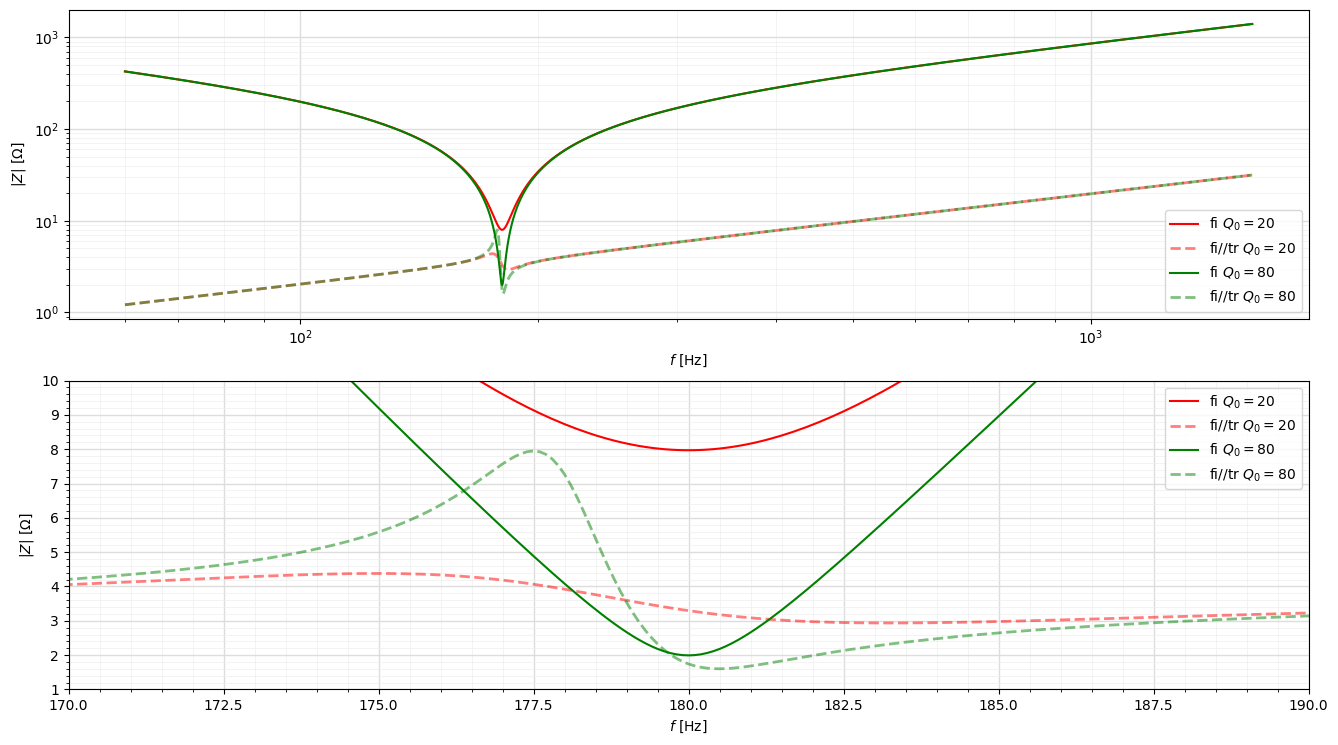

In [ ]:
fig, axs = plt.subplots(2, 1)
fig.dpi = 100
fig.set_size_inches(16, 9)

for k in range(len(FQual)):
    if k==0: cor='red'
    if k==1: cor='green'
    if k==2: cor='blue'
    leg = 'fi $Q_0=$'+str(np.round(FQual[k],0))
    axs[0].plot(f, Zmod[k], label=leg, color=cor)
    leg = 'fi//tr $Q_0=$'+str(np.round(FQual[k],0))
    axs[0].plot(f, np.abs(Z_trafoFiltro[k]), label=leg, lw=2, alpha=0.5, color=cor, ls='--')
axs[0].grid(which='major', color='#DDDDDD', linewidth=1.0)
axs[0].minorticks_on()
axs[0].grid(which='minor', color='#EEEEEE', linewidth=0.5)
#axs[0].set_ylim(1, 20)
#axs[0].set_xlim(f_fund*(h_filtrar-1/4), f_fund*(h_filtrar+1/4))
axs[0].set_ylabel('$|Z|$ [$\Omega$]')
#axs[1].plot(f, np.abs(Z_trafoFreq), label='trafo', ls='--', color='black')
axs[0].set_xlabel('$f$ [Hz]')
axs[0].legend()
axs[0].set_xscale('log')
axs[0].set_yscale('log')



for k in range(len(FQual)):
    if k==0: cor='red'
    if k==1: cor='green'
    if k==2: cor='blue'
    leg = 'fi $Q_0=$'+str(np.round(FQual[k],0))
    axs[1].plot(f, Zmod[k], label=leg, color=cor)
    leg = 'fi//tr $Q_0=$'+str(np.round(FQual[k],0))
    axs[1].plot(f, np.abs(Z_trafoFiltro[k]), label=leg, lw=2, alpha=0.5, color=cor, ls='--')
axs[1].grid(which='major', color='#DDDDDD', linewidth=1.0)
axs[1].minorticks_on()
axs[1].grid(which='minor', color='#EEEEEE', linewidth=0.5)
axs[1].set_ylim(1, 10)
axs[1].set_xlim(f_fund*(h_filtrar-1/6), f_fund*(h_filtrar+1/6))
axs[1].set_ylabel('$|Z|$ [$\Omega$]')
#axs[1].plot(f, np.abs(Z_trafoFreq), label='trafo', ls='--', color='black')
axs[1].set_xlabel('$f$ [Hz]')
axs[1].legend()


plt.show()

## Correntes Harmônicas

In [ ]:
iharm      = np.zeros((len(FQual),len(f)), dtype=np.complex_)
vharmCF    = np.zeros((len(FQual),len(f)), dtype=np.complex_)
vharmSF    = np.zeros((len(FQual),len(f)), dtype=np.complex_)
iharmF     = np.zeros((len(FQual),len(f)), dtype=np.complex_)
iharmTCF   = np.zeros((len(FQual),len(f)), dtype=np.complex_)

Y_trafoCapaci = 1j*w*C + 1/Z_trafoFreq
Z_trafoCapaci = 1 / Y_trafoCapaci

I_baseTrafo = S_trafo / ( V_fund * np.sqrt(3) )

In [ ]:
nharm = 25
itotalfiltro = np.zeros(len(FQual))
iharmint     = np.zeros((len(FQual),nharm))
vharmintCF   = np.zeros((len(FQual),nharm))
vharmintSF   = np.zeros((len(FQual),nharm))
itrafoint    = np.zeros((len(FQual),nharm))
freqint      = np.zeros(nharm)
for l in range(len(FQual)):
    kk = 0
    for k in range(len(f)):
        harm          = f[k] /f_fund
        iharm[l,k]    = I_baseTrafo / harm
        vharmCF[l,k]  = iharm[l,k] * Z_trafoFiltro[l,k]
        vharmSF[l,k]  = iharm[l,k] * Z_trafoCapaci[k]
        iharmF[l,k]   = vharmCF[l,k] / Zfiltro[l,k]
        iharmTCF[l,k] = vharmCF[l,k] / Z_trafoFreq[k]
        if (np.fmod(np.round(f[k],10), f_fund) == 0 and kk<nharm):
            freqint[kk]     = harm*f_fund
            iharmint[l,kk]  = np.abs(iharmF[l,k])
            vharmintCF[l,kk]  = np.abs(vharmCF[l,k])
            vharmintSF[l,kk]  = np.abs(vharmSF[l,k])
            itotalfiltro[l] = itotalfiltro[l] + (np.abs(iharmF[l,k]))**2
            itrafoint[l,kk] = np.abs(iharmTCF[l,k])
            kk = kk + 1
    itotalfiltro[l] = np.sqrt(itotalfiltro[l])

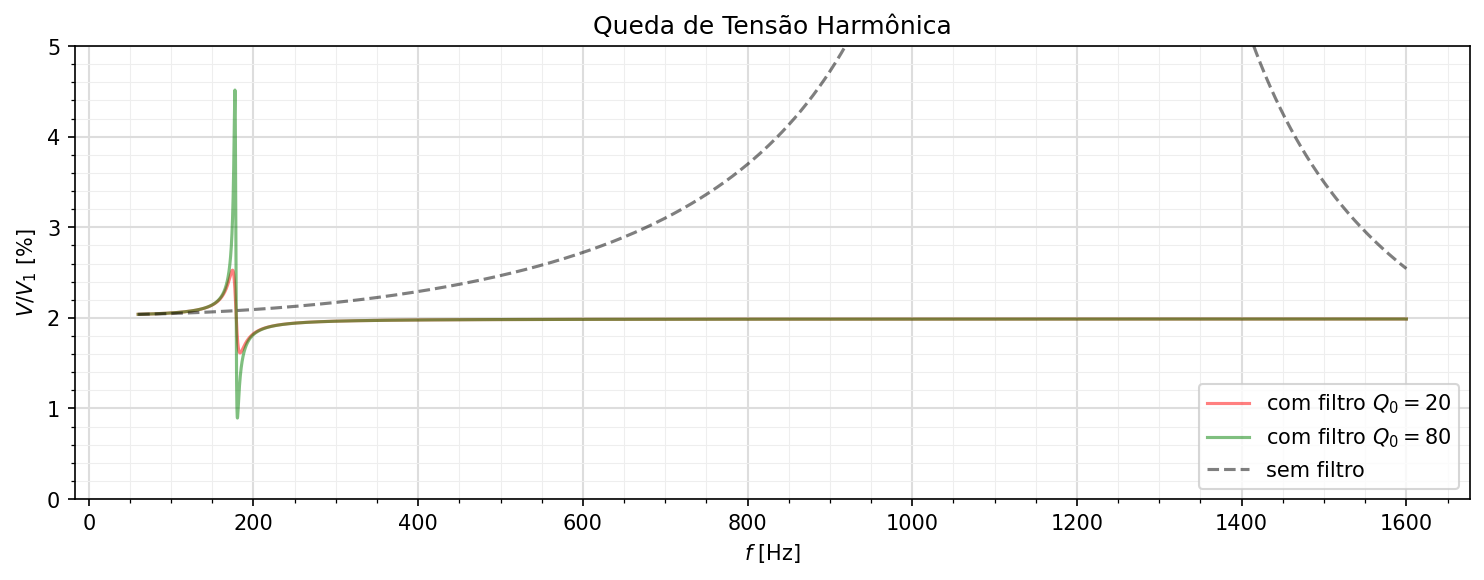

In [ ]:
plt.figure(dpi=150,figsize=(12,4))
for l in range(len(FQual)):
    if l==0: cor='red'
    if l==1: cor='green'
    if l==2: cor='blue'
    leg = 'com filtro $Q_0=$'+str(np.round(FQual[l],0))
    plt.plot( f, 100*np.abs(vharmCF[l,:])/V_fund/(np.sqrt(3)), label=leg, color = cor, alpha=0.5 )

plt.plot( f, 100*np.abs(vharmSF[0,:])/V_fund/(np.sqrt(3)), label='sem filtro', color = 'black', alpha=0.5, ls='--' )
plt.grid(which='major', color='#DDDDDD', linewidth=1.0)
plt.minorticks_on()
plt.grid(which='minor', color='#EEEEEE', linewidth=0.5)
plt.xlabel('$f$ [Hz]')
plt.ylabel('$V/V_1$ [%]')
plt.legend(loc='lower right')
plt.ylim(0,5)
plt.title('Queda de Tensão Harmônica')
plt.show()

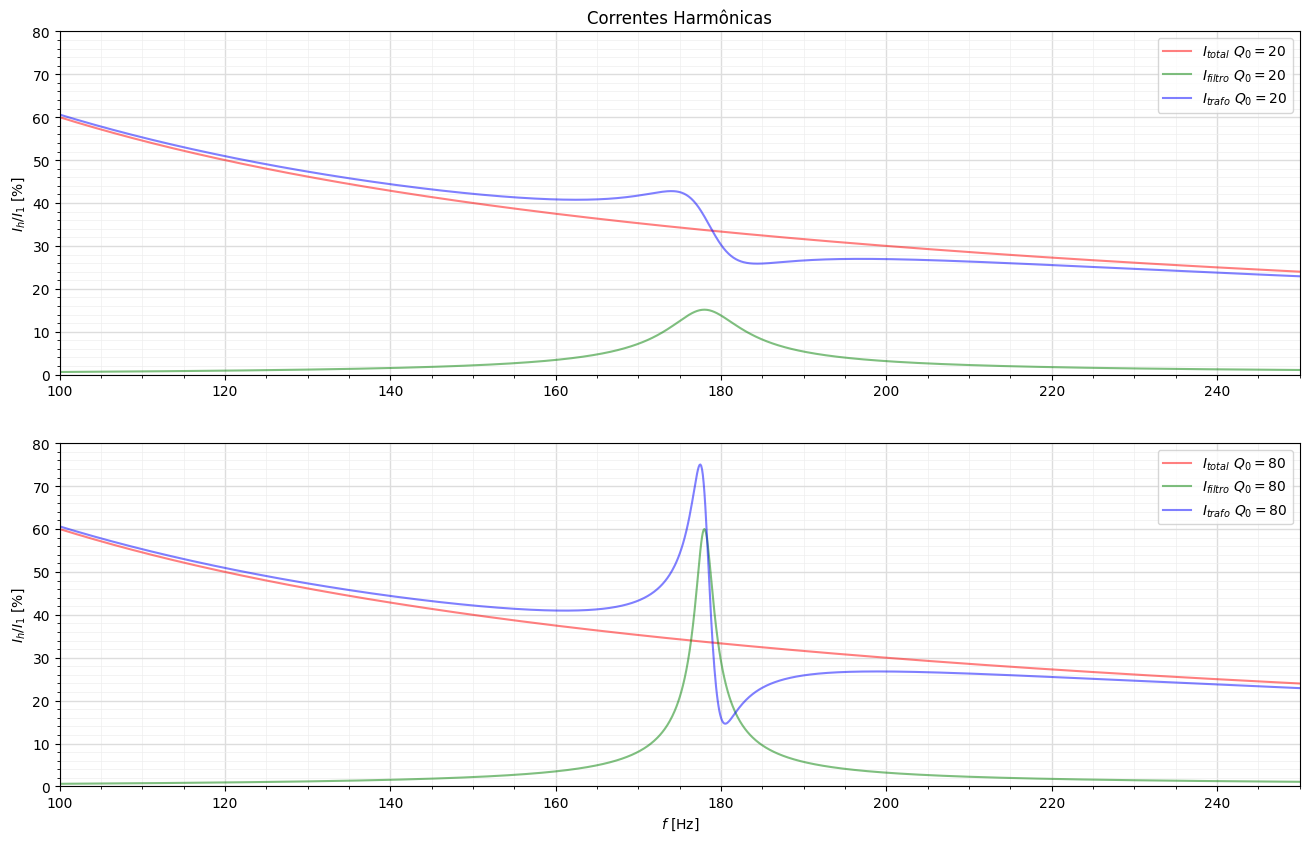

In [ ]:
fig, axs = plt.subplots(len(FQual), 1)
fig.dpi = 100
fig.set_size_inches(16, 5*len(FQual))
for l in range(len(FQual)):
    if l==0: cor='red'
    if l==1: cor='green'
    if l==2: cor='blue'
    leg = '$I_{total}$ $Q_0=$'+str(np.round(FQual[l],0))
    axs[l].plot( f, 100 *np.abs(   iharm[l,:]) /I_baseTrafo, label=leg, color = 'red',   alpha=0.5)
    leg = '$I_{filtro}$ $Q_0=$'+str(np.round(FQual[l],0))
    axs[l].plot( f, 100 *np.abs(  iharmF[l,:]) /I_baseTrafo, label=leg, color = 'green', alpha=0.5)
    leg = '$I_{trafo}$ $Q_0=$'+str(np.round(FQual[l],0))
    axs[l].plot( f, 100 *np.abs(iharmTCF[l,:]) /I_baseTrafo, label=leg, color = 'blue',  alpha=0.5)
    axs[l].grid(which='major', color='#DDDDDD', linewidth=1.0)
    axs[l].minorticks_on()
    axs[l].grid(which='minor', color='#EEEEEE', linewidth=0.5)
    axs[l].set_ylabel('$I_h/I_1$ [%]')
    axs[l].legend(loc='upper right')
    axs[l].set_xlim(100,250)
    axs[l].set_ylim(0,80)
axs[0].set_title('Correntes Harmônicas')
plt.xlabel('$f$ [Hz]')
plt.show()

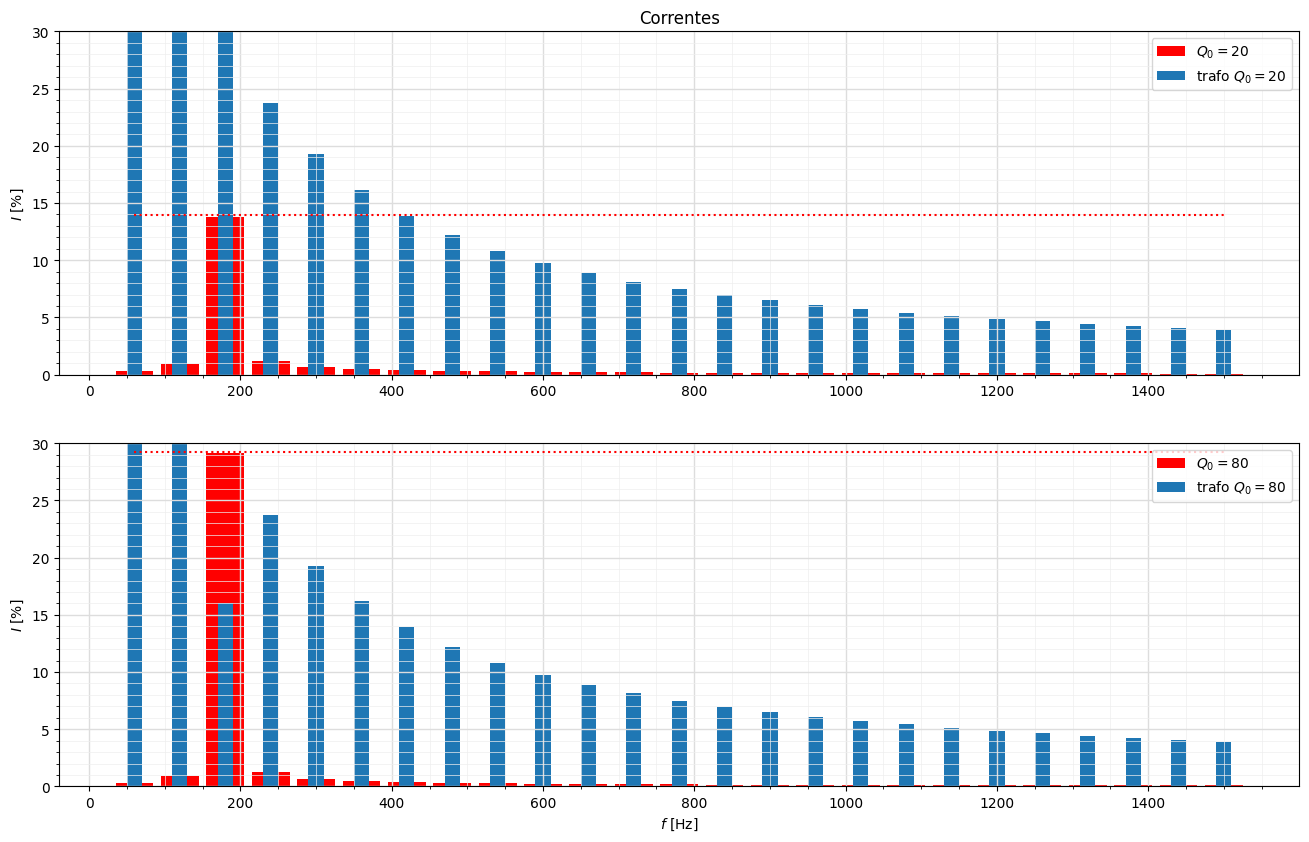

In [ ]:
#maxY = round(1.1*np.max(iharmint))
fig, axs = plt.subplots(len(FQual), 1)
fig.dpi = 100
fig.set_size_inches(16, 5*len(FQual))
for l in range(len(FQual)):
    if l==0: cor='red'
    if l==1: cor='green'
    if l==2: cor='blue'
    leg = '$Q_0=$'+str(np.round(FQual[l],0))
    axs[l].bar(freqint, 100*iharmint[l,:]/I_baseTrafo, 50, label=leg, color = 'red')
    leg = 'trafo $Q_0=$'+str(np.round(FQual[l],0))
    axs[l].bar(freqint, 100*itrafoint[l,:]/I_baseTrafo, 20, label=leg)
    axs[l].plot(freqint, 100*np.ones(nharm)*itotalfiltro[l]/I_baseTrafo, ls=":", color='red')
    axs[l].grid(which='major', color='#DDDDDD', linewidth=1.0)
    axs[l].minorticks_on()
    axs[l].grid(which='minor', color='#EEEEEE', linewidth=0.5)
    axs[l].set_ylabel('$I$ [%]')
    axs[l].legend(loc='upper right')
    axs[l].set_ylim(0,30)

axs[0].set_title('Correntes')
axs[len(FQual)-1].set_xlabel('$f$ [Hz]')
plt.show()

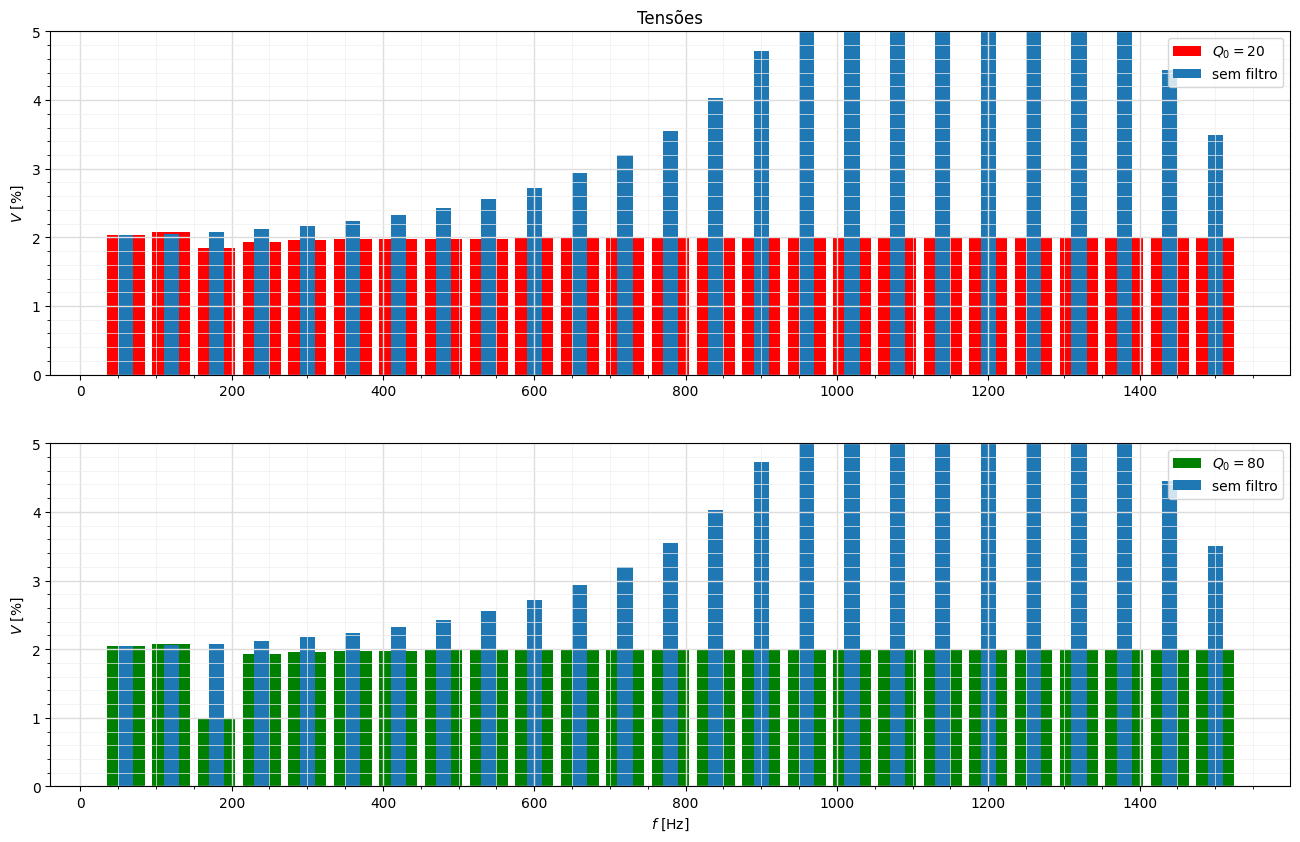

In [ ]:
fig, axs = plt.subplots(len(FQual), 1)
fig.dpi = 100
fig.set_size_inches(16, 5*len(FQual))
for l in range(len(FQual)):
    if l==0: cor='red'
    if l==1: cor='green'
    if l==2: cor='blue'
    leg = '$Q_0=$'+str(np.round(FQual[l],0))
    axs[l].bar(freqint, 100*vharmintCF[l,:]/(V_fund*np.sqrt(3)), 50, label=leg, color = cor)
    leg = 'sem filtro'
    axs[l].bar(freqint, 100*vharmintSF[l,:]/(V_fund*np.sqrt(3)), 20, label=leg)
    axs[l].grid(which='major', color='#DDDDDD', linewidth=1.0)
    axs[l].minorticks_on()
    axs[l].grid(which='minor', color='#EEEEEE', linewidth=0.5)
    axs[l].set_ylabel('$V$ [%]')
    axs[l].legend(loc='upper right')
    axs[l].set_ylim(0,5)

axs[0].set_title('Tensões')
axs[len(FQual)-1].set_xlabel('$f$ [Hz]')
plt.show()